# **CÀI THƯ VIỆN & ĐỌC DỮ LIỆU**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import math
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from math import sqrt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

In [2]:
from google.colab import files
uploaded = files.upload()

Saving df_weather.csv to df_weather.csv


In [3]:
requests = pd.read_csv("/content/df_weather.csv")
requests.head()

,location.name,location.region,location.country,location.lat,location.lon,location.tz_id,location.localtime_epoch,location.localtime,date,date_epoch,...,day.condition.text,day.condition.icon,day.condition.code,day.uv,astro.sunrise,astro.sunset,astro.moonrise,astro.moonset,astro.moon_phase,astro.moon_illumination
0,An Giang,Nam,Vietnam,10.7000,105.1167,Asia/Ho_Chi_Minh,1745362412,4/23/2025 5:53,4/21/2024,1713657600,...,Sunny,//cdn.weatherapi.com/weather/64x64/day/113.png,1000,9,5:46 AM,6:11 PM,4:13 PM,3:55 AM,Waxing Gibbous,90
1,Ba Ria-Vung Tau,Nam,Vietnam,10.3500,107.0667,Asia/Ho_Chi_Minh,1745361919,4/23/2025 5:45,4/21/2024,1713657600,...,Moderate rain at times,//cdn.weatherapi.com/weather/64x64/day/299.png,1186,7,5:38 AM,6:03 PM,4:05 PM,3:47 AM,Waxing Gibbous,90
2,Bac Giang,Bac,Vietnam,21.2667,106.2000,Asia/Bangkok,1745362885,4/23/2025 6:01,4/21/2024,1713657600,...,Heavy rain at times,//cdn.weatherapi.com/weather/64x64/day/305.png,1192,7,5:32 AM,6:16 PM,4:09 PM,3:53 AM,Waxing Gibbous,90
3,Bac Kan,Bac,Vietnam,22.1333,105.8333,Asia/Bangkok,1745362887,4/23/2025 6:01,4/21/2024,1713657600,...,Moderate or heavy rain shower,//cdn.weatherapi.com/weather/64x64/day/356.png,1243,6,5:32 AM,6:19 PM,4:10 PM,3:54 AM,Waxing Gibbous,90
4,Bac Lieu,Nam,Vietnam,9.2850,105.7244,Asia/Ho_Chi_Minh,1745361922,4/23/2025 5:45,4/21/2024,1713657600,...,Partly cloudy,//cdn.weatherapi.com/weather/64x64/day/116.png,1003,9,5:45 AM,6:07 PM,4:11 PM,3:52 AM,Waxing Gibbous,90


# **LỌC DỮ LIỆU MIỀN TRUNG**

In [4]:
# Danh sách tỉnh miền Trung có thể điều chỉnh tuỳ ý
central_provinces = [
    "Da Nang", "Thua Thien Hue", "Quang Nam", "Quang Ngai",
    "Binh Dinh", "Phu Yen", "Khanh Hoa", "Quang Tri", "Ha Tinh",
    "Nghe An","Quang Binh","Quang Ngai","Ninh Thuan","Binh Thuan"
]

# Include necessary weather columns when creating df_central
df_central = requests[requests['location.name'].isin(central_provinces)].copy()
df_central = df_central[['date', 'location.name', 'day.totalprecip_mm', 'day.maxtemp_c', 'day.mintemp_c', 'day.avgtemp_c', 'day.avghumidity']].copy() # Added .copy() to avoid SettingWithCopyWarning
df_central['date'] = pd.to_datetime(df_central['date'], errors='coerce') # Convert 'date' to datetime
df_central = df_central.dropna(subset=['date', 'location.name', 'day.totalprecip_mm'])
df_central = df_central.sort_values(by='date')
available_provinces = [p for p in requests['location.name'].unique() if any(c in p for c in central_provinces)]

# **CHUẨN HOÁ DỮ LIỆU & TẠO DỮ LIỆU ĐẦU VÀO**

In [5]:
# Chuẩn hoá dữ liệu
scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(requests[['day.avgtemp_c']])

# Hàm tạo chuỗi thời gian
def create_sequences(data, window_size=7):
    X, y = [], []
    for i in range(window_size, len(data)):
        X.append(data[i-window_size:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

window_size = 7
X, y = create_sequences(data_scaled, window_size)

# Định hình lại đầu vào cho LSTM: (mẫu, bước thời gian, tính năng)
X = X.reshape((X.shape[0], X.shape[1], 1))

# Chia train/test
split = int(len(X)*0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# **TIỀN XỬ LÝ CHUỖI THỜI GIAN**

In [6]:
scaler = MinMaxScaler()
rain_by_date = df_central.groupby('date')['day.totalprecip_mm'].sum().reset_index()
rain_by_date.columns = ['date', 'total_rain']
rain_scaled = scaler.fit_transform(rain_by_date[['total_rain']])

def create_sequences(data, window_size=7):
    X, y = [], []
    for i in range(window_size, len(data)):
        X.append(data[i-window_size:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

window_size = 7
X, y = create_sequences(rain_scaled, window_size)

rainfall_data_by_province = {}
for province in available_provinces:
    df_p = df_central[df_central['location.name'] == province][['date', 'day.totalprecip_mm']].copy()
    df_p.columns = ['date', 'rainfall']
    df_p['date'] = pd.to_datetime(df_p['date'], errors='coerce')
    df_p = df_p.dropna(subset=['date']).sort_values(by='date').set_index('date')
    df_p = df_p.dropna(subset=['rainfall'])
    if len(df_p) >= 60:
        rainfall_data_by_province[province] = df_p

# Chia train/test
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Định hình lại cho LSTM
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# **HÀM TẠO CHUỖI DỮ LIỆU**

In [7]:
def create_sequences(data, time_steps=30):
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data[i:i+time_steps])
        y.append(data[i+time_steps])
    return np.array(X), np.array(y)

# **XÂY MÔ HÌNH LSTM**

In [ ]:
model = Sequential()
model.add(LSTM(units=64, activation='tanh', input_shape=(window_size, 1)))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')

history = model.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_test, y_test))

forecast_results = {}
for province, df_rain in rainfall_data_by_province.items():
    data = df_rain[['rainfall']].values
    scaler = MinMaxScaler()
    scaled_data = scaler.fit_transform(data)
    X, y = create_sequences(scaled_data, time_steps=30)
    if len(X) < 10:
        continue
    split = int(len(X) * 0.8)
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]
    model = Sequential()
    model.add(LSTM(64, return_sequences=False, input_shape=(30, 1)))
    model.add(Dense(1))
    model.compile(optimizer='adam', loss='mean_squared_error')
    model.fit(X_train, y_train, epochs=10, batch_size=16, verbose=0)
    y_pred = model.predict(X_test)
    y_pred_inv = scaler.inverse_transform(y_pred)
    y_test_inv = scaler.inverse_transform(y_test)
    rmse = math.sqrt(mean_squared_error(y_test_inv, y_pred_inv))
    last_seq = scaled_data[-30:].reshape(1, 30, 1)
    future = []
    for _ in range(7):
        next_val = model.predict(last_seq)[0]
        future.append(next_val)
        last_seq = np.append(last_seq[:, 1:, :], [[next_val]], axis=1)
    forecast = scaler.inverse_transform(np.array(future).reshape(-1, 1))
    forecast_results[province] = {
        'rmse': rmse,
        'forecast_7_days': forecast.flatten().tolist()
    }

Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0241 - val_loss: 0.0078
Epoch 2/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0121 - val_loss: 0.0039
Epoch 3/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0114 - val_loss: 0.0041
Epoch 4/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0101 - val_loss: 0.0038
Epoch 5/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0101 - val_loss: 0.0041
Epoch 6/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0093 - val_loss: 0.0038
Epoch 7/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0131 - val_loss: 0.0039
Epoch 8/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0207 - val_loss: 0.0033
Epoch 9/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0130 - val_loss: 0.0035
Epoch 10/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0110 - val_loss: 0.0038
Epoch 11/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0132 - val_loss: 0.0037
Epoch 12/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0099 - val_loss: 0.

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


...

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


# **HÀM MẤT MÁT**

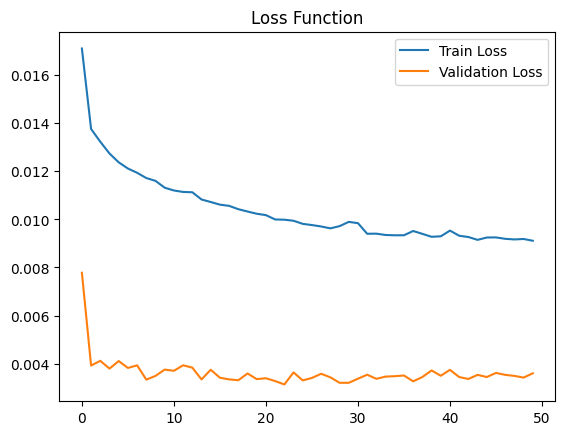

In [ ]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend(); plt.title("Loss Function"); plt.show()

# **DỰ BÁO & ĐÁNH GIÁ**

**Sai số trung bình bình phương căn bậc hai**

In [ ]:
df = pd.read_csv('/content/df_weather.csv')
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df_temp = df[df['location.name'] == 'Da Nang'][['date', 'day.avgtemp_c']]
df_temp = df_temp.dropna().sort_values('date')
df_temp.reset_index(drop=True, inplace=True)


predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)
preds_scaled = model.predict(X_test)
preds = scaler.inverse_transform(preds_scaled)
y_test_rescaled = scaler.inverse_transform(y_test.reshape(-1, 1))
y_true = scaler.inverse_transform(y_test.reshape(-1, 1))


rmse = sqrt(mean_squared_error(y_test_rescaled, preds))
print(f"RMSE mô hình: {rmse:.2f} mm")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
RMSE mô hình: 8.53 mm


**Biểu đồ nhiệt độ và lượng mưa với màu theo độ ẩm**

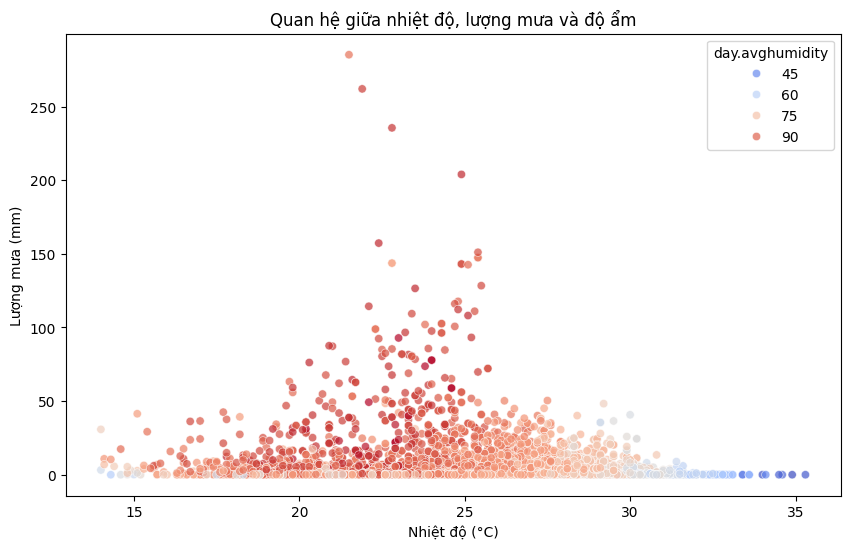

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df_central,
    x='day.avgtemp_c',
    y='day.totalprecip_mm',
    hue='day.avghumidity',
    palette='coolwarm',
    alpha=0.7
)
plt.title('Quan hệ giữa nhiệt độ, lượng mưa và độ ẩm')
plt.xlabel('Nhiệt độ (°C)')
plt.ylabel('Lượng mưa (mm)')
# Đã xóa plt.colorbar() để seaborn có thể xử lý nó.
plt.show()

**Biểu đồ phân phối lượng mưa và nhiệt độ**

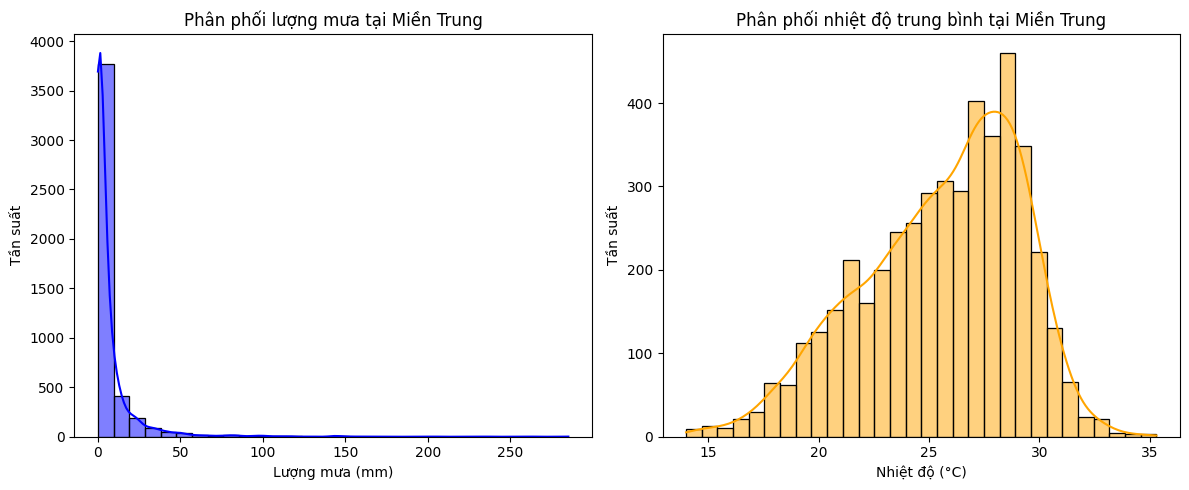

In [ ]:
plt.figure(figsize=(12,5))

# Phân phối lượng mưa
plt.subplot(1,2,1)
sns.histplot(df_central['day.totalprecip_mm'], kde=True, color='blue', bins=30)
plt.title('Phân phối lượng mưa tại Miền Trung')
plt.xlabel('Lượng mưa (mm)')
plt.ylabel('Tần suất')

# Phân phối nhiệt độ trung bình
plt.subplot(1,2,2)
sns.histplot(df_central['day.avgtemp_c'], kde=True, color='orange', bins=30)
plt.title('Phân phối nhiệt độ trung bình tại Miền Trung')
plt.xlabel('Nhiệt độ (°C)')
plt.ylabel('Tần suất')

plt.tight_layout()
plt.show()

**Biểu đồ dự báo lượng mưa tại Miền Trung**

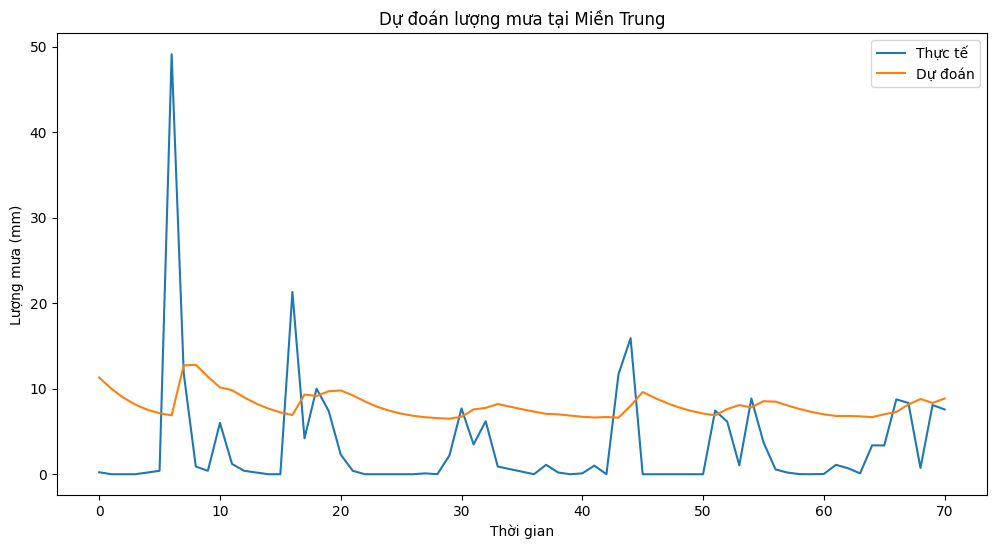

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(y_test_rescaled, label='Thực tế')
plt.plot(preds, label='Dự đoán')
plt.title('Dự đoán lượng mưa tại Miền Trung')
plt.xlabel('Thời gian')
plt.ylabel('Lượng mưa (mm)')
plt.legend()
plt.show()

**Biểu đồ tổng lượng mưa miền Trung theo tháng & năm**

In [ ]:
rain_by_date = df_central.groupby('date')['day.totalprecip_mm'].sum().reset_index()
rain_by_date.rename(columns={'day.totalprecip_mm': 'total_rain'}, inplace=True)
fig = px.line(rain_by_date, x='date', y='total_rain', title='Tổng lượng mưa miền Trung theo tháng & năm')
fig.update_layout(xaxis_title='Tháng & Năm', yaxis_title='Tổng lượng mưa (mm)')
fig.show()

**Biểu đồ biến động lượng mưa tại miền Trung ( 30 ngày )**

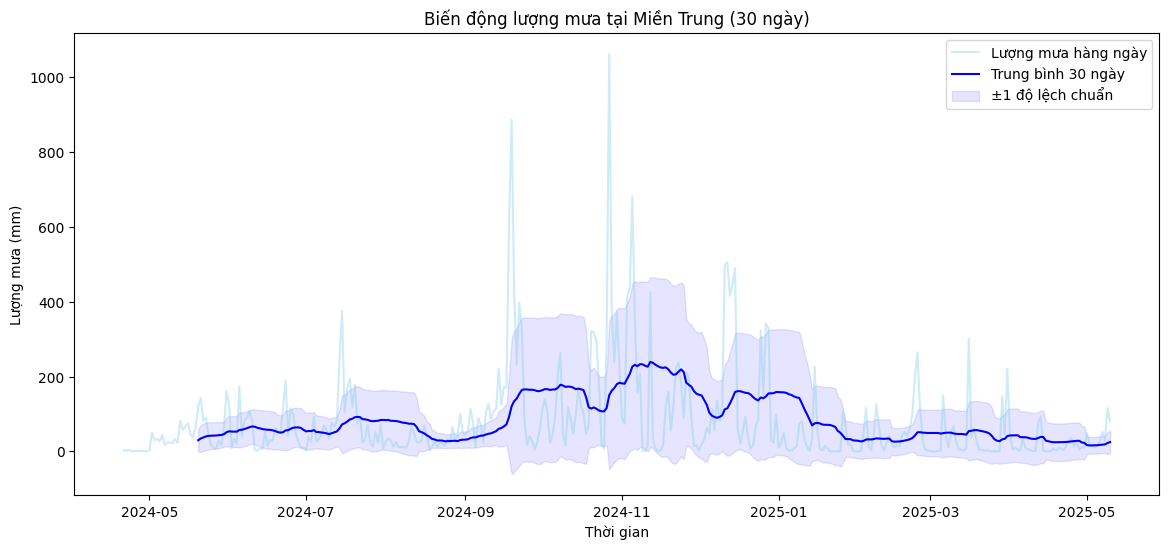

In [ ]:
rain_by_date = df_central.groupby('date')['day.totalprecip_mm'].sum().reset_index()
rain_by_date['rolling_mean'] = rain_by_date['day.totalprecip_mm'].rolling(30).mean()
rain_by_date['rolling_std'] = rain_by_date['day.totalprecip_mm'].rolling(30).std()

plt.figure(figsize=(14,6))
plt.plot(rain_by_date['date'], rain_by_date['day.totalprecip_mm'], color='skyblue', alpha=0.4, label='Lượng mưa hàng ngày')
plt.plot(rain_by_date['date'], rain_by_date['rolling_mean'], color='blue', label='Trung bình 30 ngày')
plt.fill_between(rain_by_date['date'],
                 rain_by_date['rolling_mean'] - rain_by_date['rolling_std'],
                 rain_by_date['rolling_mean'] + rain_by_date['rolling_std'],
                 color='blue', alpha=0.1, label='±1 độ lệch chuẩn')
plt.title('Biến động lượng mưa tại Miền Trung (30 ngày)')
plt.xlabel('Thời gian')
plt.ylabel('Lượng mưa (mm)')
plt.legend()
plt.show()

**Biểu đồ tổng lượng mưa theo tỉnh**

/tmp/ipython-input-3302933666.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




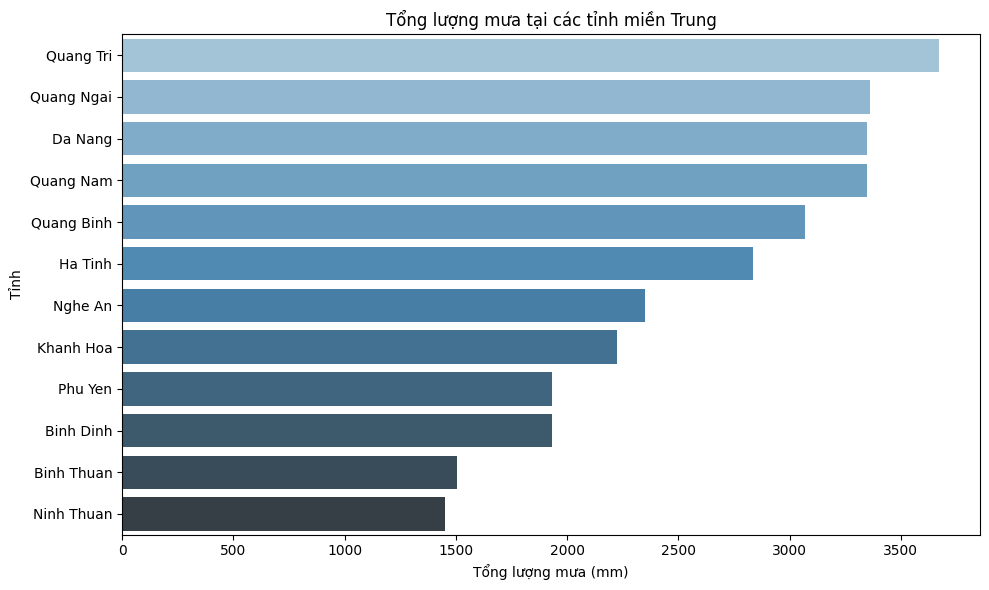

In [ ]:
rain_total = df_central.groupby('location.name')['day.totalprecip_mm'].sum().reset_index().sort_values(by='day.totalprecip_mm', ascending=False)
plt.figure(figsize=(10,6))
sns.barplot(data=rain_total, x='day.totalprecip_mm', y='location.name', palette='Blues_d')
plt.xlabel('Tổng lượng mưa (mm)')
plt.ylabel('Tỉnh')
plt.title('Tổng lượng mưa tại các tỉnh miền Trung')
plt.tight_layout()
plt.show()

**Biểu đồ nhiệt độ trung bình theo ngày - Đà Nẵng**

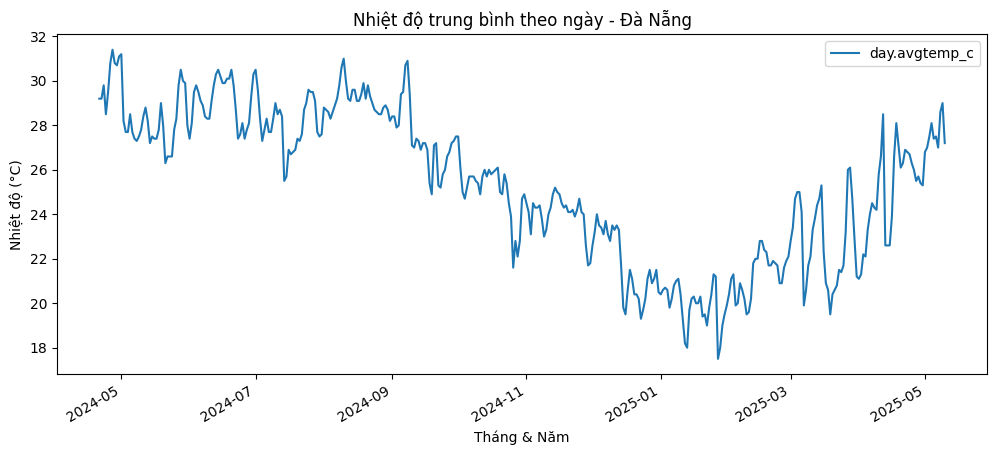

In [ ]:
df_temp.plot(x='date', y='day.avgtemp_c', figsize=(12,5), title='Nhiệt độ trung bình theo ngày - Đà Nẵng')
plt.xlabel('Tháng & Năm')
plt.ylabel('Nhiệt độ (°C)')
plt.show()

# **MA TRẬN LƯỢNG MƯA THEO THÁNG VÀ TỈNH**

In [ ]:
# Chuyển cột 'date' sang datetime nếu chưa
df_central['date'] = pd.to_datetime(df_central['date'])

# Tạo cột 'month' và 'year'
df_central['month'] = df_central['date'].dt.month
df_central['year'] = df_central['date'].dt.year

# Tính tổng lượng mưa theo tỉnh và tháng
rain_matrix = df_central.pivot_table(
    values='day.totalprecip_mm',
    index='location.name',
    columns='month',
    aggfunc='sum'
).fillna(0)

rain_matrix.head()

month,1,2,3,4,5,6,7,8,9,10,11,12
location.name,,,,,,,,,,,,
Binh Dinh,33.74,76.46,76.37,5.17,115.31,133.24,113.66,90.70,221.43,333.14,237.58,497.13
Binh Thuan,18.10,20.90,26.61,25.32,152.33,181.59,301.40,134.98,237.29,224.04,36.65,145.19
Da Nang,119.50,219.52,167.12,38.20,153.81,197.10,263.10,98.05,532.62,534.70,598.02,427.92
Ha Tinh,55.10,128.62,120.48,107.27,234.14,132.80,229.49,40.30,653.78,353.80,511.88,269.83
Khanh Hoa,39.00,88.25,73.55,20.39,112.10,174.16,221.85,96.03,270.57,357.67,221.35,547.78


**Ma trận tương quan giữa các biến**

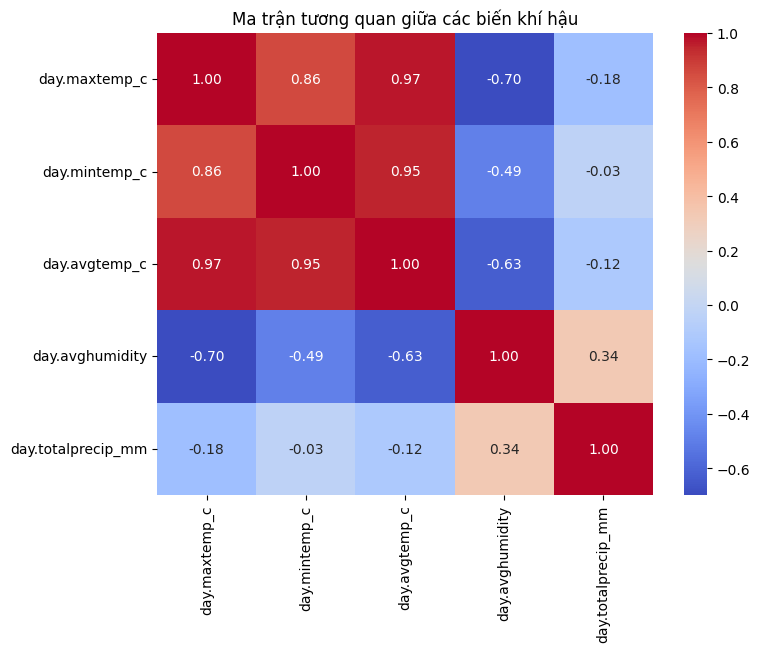

In [ ]:
# Chọn các cột liên quan khí tượng
weather_vars = df[df['location.name'].isin(central_provinces)][['day.maxtemp_c', 'day.mintemp_c', 'day.avgtemp_c', 'day.avghumidity', 'day.totalprecip_mm']]

# Tính ma trận tương quan
corr_matrix = weather_vars.corr()

# Hiển thị với seaborn
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Ma trận tương quan giữa các biến khí hậu')
plt.show()

**Ma trận đếm số ngày có mưa to/nhẹ/vừa tại từng tỉnh**

In [ ]:
# Thêm cột tháng và mùa
df_central['month'] = df_central['date'].dt.month
df_central['season'] = df_central['month'].apply(
    lambda x: 'Mùa Khô' if x in [1,2,3,4,5,6,7,8]
    else 'Mùa Mưa'
)
# Phân loại lượng mưa
def classify_rain(mm):
    if mm == 0:
        return 'Không mưa'
    elif mm < 20:
        return 'Mưa nhẹ'
    elif mm < 50:
        return 'Mưa vừa'
    elif mm < 100:
        return 'Mưa to'
    else:
        return 'Mưa rất to'

df_central['rain_level'] = df_central['day.totalprecip_mm'].apply(classify_rain)

rain_level_matrix = df_central.pivot_table(
    values='date',
    index='location.name',
    columns='rain_level',
    aggfunc='count'
).fillna(0)

rain_level_matrix

rain_level,Không mưa,Mưa nhẹ,Mưa rất to,Mưa to,Mưa vừa
location.name,,,,,
Binh Dinh,76.0,279.0,0.0,2.0,27.0
Binh Thuan,129.0,242.0,0.0,1.0,12.0
Da Nang,55.0,285.0,4.0,9.0,31.0
Ha Tinh,122.0,223.0,4.0,8.0,27.0
Khanh Hoa,85.0,264.0,0.0,3.0,32.0
Nghe An,118.0,235.0,3.0,6.0,22.0
Ninh Thuan,110.0,257.0,1.0,4.0,12.0
Phu Yen,76.0,279.0,0.0,2.0,27.0
Quang Binh,63.0,290.0,4.0,3.0,24.0


# **PHÂN TÍCH LƯỢNG MƯA THEO MÙA Ở MIỀN TRUNG**

**Biểu đồ tròn phân loại mưa**

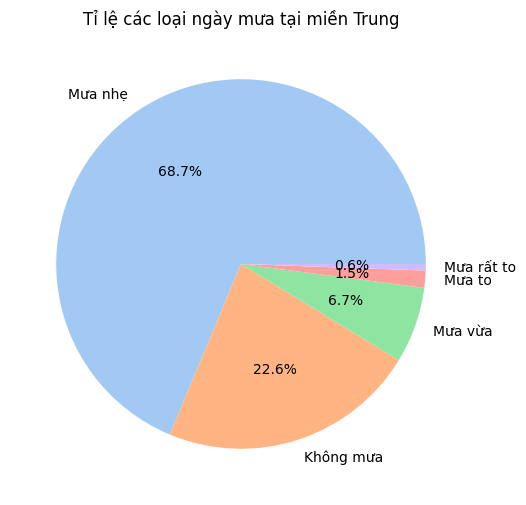

In [ ]:
rain_level_counts = df_central['rain_level'].value_counts().reset_index()
rain_level_counts.columns = ['Loại mưa', 'Số ngày']

plt.figure(figsize=(6,6))
plt.pie(rain_level_counts['Số ngày'], labels=rain_level_counts['Loại mưa'], autopct='%1.1f%%', colors=sns.color_palette('pastel'))
plt.title('Tỉ lệ các loại ngày mưa tại miền Trung')
plt.show()

**Phân tích lượng mưa theo mùa**

/tmp/ipython-input-818341476.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




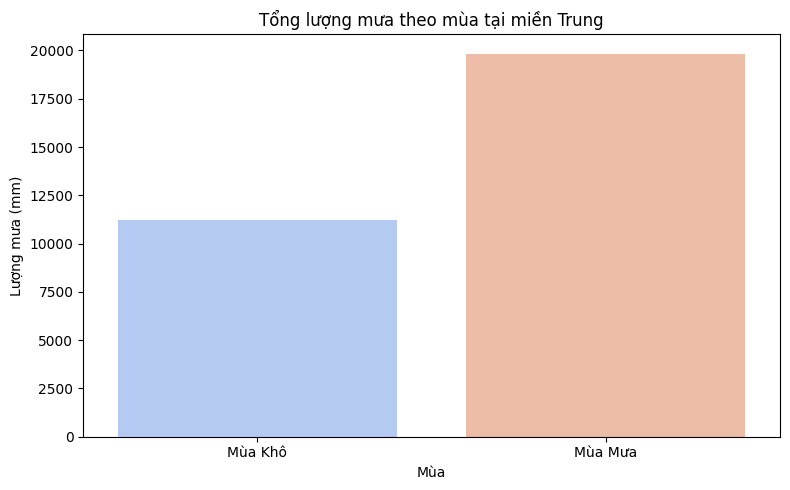

In [ ]:
rain_by_season = df_central.groupby('season')['day.totalprecip_mm'].sum().reset_index()

plt.figure(figsize=(8,5))
sns.barplot(data=rain_by_season, x='season', y='day.totalprecip_mm', palette='coolwarm')
plt.title('Tổng lượng mưa theo mùa tại miền Trung')
plt.ylabel('Lượng mưa (mm)')
plt.xlabel('Mùa')
plt.tight_layout()
plt.show()

**Biểu đồ mưa cực đoan**

In [ ]:
# Lọc các ngày mưa cực đoan (top 5%)
threshold_extreme = df_central['day.totalprecip_mm'].quantile(0.95)
extreme_rain = df_central[df_central['day.totalprecip_mm'] >= threshold_extreme]

plt.figure(figsize=(12,6))
sns.scatterplot(
    data=extreme_rain,
    x='date',
    y='day.totalprecip_mm',
    hue='location.name',
    palette='Set1'
)
plt.axhline(threshold_extreme, color='red', linestyle='--', label='Ngưỡng 5% cao nhất')
plt.title('Các ngày mưa cực đoan tại Miền Trung')
plt.xlabel('Thời gian')
plt.ylabel('Lượng mưa (mm)')
plt.legend(title='Tỉnh', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

# **SO SÁNH CÁC TỈNH MIỀN TRUNG**

**Biểu đồ so sánh lượng mưa tháng tại từng tỉnh**

In [ ]:
g = sns.FacetGrid(df_central, col="location.name", col_wrap=4, height=5, sharey=False)
g.map_dataframe(sns.lineplot, x="date", y="day.totalprecip_mm", color="blue")
g.set_titles("{col_name}")
g.set_axis_labels("Tháng", "Lượng mưa (mm)")
plt.subplots_adjust(top=0.9)
g.fig.suptitle('So sánh lượng mưa tháng tại từng tỉnh Miền Trung')
plt.show()

**Biểu đồ so sánh nhiệt độ giữa các tỉnh**

In [ ]:
plt.figure(figsize=(12,6))
sns.violinplot(
    data=df_central,
    x='location.name',
    y='day.avgtemp_c',
    palette='muted'
)
plt.title('Phân bố nhiệt độ tại các tỉnh Miền Trung')
plt.xlabel('Tỉnh')
plt.ylabel('Nhiệt độ (°C)')
plt.xticks(rotation=45)
plt.show()

# **DỰ BÁO NGÀY TIẾP THEO CỦA LƯỢNG MƯA VÀ NHIỆT ĐỘ**

**Lượng mưa trung bình 7 ngày gần nhất**

In [ ]:
rain_by_date = df_central.groupby('date')['day.totalprecip_mm'].mean().reset_index()
rain_by_date.columns = ['date', 'avg_rain']
rain_by_date = rain_by_date.sort_values(by='date')


last_7_days_rain = rain_by_date.tail(7)
print("Lượng mưa trung bình 7 ngày gần nhất:")
print(last_7_days_rain)

da_nang_forecast = forecast_results.get('Da Nang')

if da_nang_forecast:
    next_day_pred = da_nang_forecast['forecast_7_days'][0]
    print(f"Dự báo lượng mưa ngày tiếp theo tại Đà Nẵng: {next_day_pred:.2f} mm")
else:
    print("Forecast results for Da Nang not available.")

**Nhiệt độ trung bình 7 ngày gần nhất**

In [ ]:
scaler = MinMaxScaler()
temp_by_date = df_temp.groupby('date')['day.avgtemp_c'].mean().reset_index()
temp_by_date.columns = ['date', 'avg_temp']

scaler.fit(temp_by_date[['avg_temp']])
temp_scaled = scaler.transform(temp_by_date[['avg_temp']])

last_7_days = temp_scaled[-7:].reshape(1, 7, 1)
next_day_scaled = model.predict(last_7_days)

print("Nhiệt độ trung bình 7 ngày gần nhất:")
print(temp_by_date.tail(7))

next_day_temp = scaler.inverse_transform(next_day_scaled)
print(f"Nhiệt độ trung bình dự báo cho ngày tiếp theo là: {next_day_temp[0][0]:.2f} °C")

**Kết quả dự báo**

In [ ]:
for province, result in forecast_results.items():
    print(f"\n--- {province} ---")
    print(f"RMSE: {result['rmse']:.2f}")
    print("Dự báo 7 ngày tới (mm):", result['forecast_7_days'])

# **BẢN ĐỒ THỰC TẾ LƯỢNG MƯA TẠI MIỀN TRUNG**

In [ ]:
!pip install folium

In [ ]:
import folium
from folium.plugins import MarkerCluster

# Tổng lượng mưa theo tỉnh
rain_total = df_central.groupby('location.name')['day.totalprecip_mm'].sum().reset_index()
rain_total.columns = ['Province', 'TotalRain']

# Tạo bản đồ trung tâm Việt Nam
central_vn_map = folium.Map(location=[15.5, 108], zoom_start=6)

# Danh sách kinh độ - vĩ độ của một số tỉnh miền Trung
province_coords = {
    "Da Nang": [16.0471, 108.2062],
    "Thua Thien Hue": [16.4637, 107.5909],
    "Quang Nam": [15.5394, 108.0191],
    "Quang Ngai": [15.1205, 108.7922],
    "Binh Dinh": [13.7820, 109.2196],
    "Phu Yen": [13.0882, 109.0929],
    "Khanh Hoa": [12.2585, 109.0524],
    "Quang Tri": [16.7403, 107.1897],
    "Ha Tinh": [18.3559, 105.8875],
    "Nghe An": [19.2342, 104.9200],
    "Quang Binh": [17.4689, 106.6223],
    "Ninh Thuan": [11.6739, 109.0033],
    "Binh Thuan": [11.0904, 108.0721],
}

# Thêm điểm vào bản đồ
for _, row in rain_total.iterrows():
    province = row['Province']
    rain = row['TotalRain']
    coords = province_coords.get(province)
    if coords:
        folium.CircleMarker(
            location=coords,
            radius=10,
            color='blue',
            fill=True,
            fill_color='blue',
            fill_opacity=0.6,
            popup=f"{province}: {rain:.1f} mm"
        ).add_to(central_vn_map)

# Hiển thị bản đồ
central_vn_map